# 1 · Data preparation

Merged from the former notebooks 01, 02 and 04. Cells and saved outputs are unchanged from their original runs; the merge did not re-execute anything. Only the setup cell (one, at the top) and the headings were edited.

**Contents**
- **Part A · Forecasting data audit (station 8160)**: hourly → daily PM2.5, coverage and eligibility, the event threshold, baseline scores (test winter sealed).
- **Part B · Network data audit (agaar.gov.mn, Ulaanbaatar)**: agaar.gov.mn stations: cleaning, coverage per split, eligible stations, redundancy, threshold.
- **Part C · Weather and forecast features (ERA5)**: ERA5 download, daily weather, the BLH availability rule, the feature table and usable rows.

In [1]:
# Setup
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from uaq.config import load_config, ROOT
from uaq import weather, features
from uaq.io import load_hourly
from uaq.daily import to_daily
from uaq.periods import assign_split, in_months
cfg = load_config()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
%matplotlib inline
print("Project root:", ROOT)

Project root: /Users/user/Desktop/neural


## Part A · Forecasting data audit (station 8160)

**Goal:** check that the hourly PM2.5 record is good enough for next-day forecasting, and lock the decisions the models depend on.

**Needs:** OpenAQ archive files for location 8160 anywhere under `data/raw/pm25/` (e.g. `data/raw/pm25/openaq/8160/`).
For a dry run without real data: `python scripts/make_synthetic_data.py` from the repo root (fake data, delete it afterwards).

All logic lives in `src/uaq/` (`io.py`, `daily.py`, `audit_forecast.py`, `thresholds.py`, `baselines.py`); this notebook runs it step by step.

### A.1 · Study design from the config
Every date here is locked. The test winter (2024/25) is never scored in this notebook.

In [2]:
fp = cfg["forecast"]["periods"]
display(pd.DataFrame(fp["split"]).T.rename_axis("split"))
print("Core:", fp["core"], "| Pre-ban sensitivity:", fp["pre_ban_sensitivity"])
VAL_END = pd.Timestamp(fp["split"]["val"]["end"])   # PM2.5 values after this date stay sealed (project rule 1: test seal)
print("Smog season months:", cfg["smog_months"], "| Raw-coal ban:", cfg["structural_break"])

,start,end
split,,
train,2019-07-01,2023-06-30
val,2023-07-01,2024-06-30
test,2024-07-01,2025-03-31


Core: {'start': '2019-07-01', 'end': '2025-03-31'} | Pre-ban sensitivity: {'start': '2016-11-09', 'end': '2019-06-30'}
Smog season months: [11, 12, 1, 2] | Raw-coal ban: 2019-05-15


### A.2 · Load the hourly data
Timestamps are converted to Ulaanbaatar local time. Negative values become missing; values above the plausibility bound are **flagged, not deleted**, because winter peaks are genuinely extreme.

In [3]:
from uaq.io import load_hourly
hourly = load_hourly(cfg)
print(hourly.attrs)
print("Rows:", len(hourly), "| from", hourly["ts_local"].min(), "to", hourly["ts_local"].max())
hourly.head()

{'files': 3181, 'units_seen': ['µg/m³'], 'dropped_bad_timestamps': 0, 'duplicate_station_hours': 0}
Rows: 61607 | from 2016-11-09 17:00:00 to 2025-03-04 12:00:00


,station_id,ts_local,station_name,pm25,lat,lon,flag_implausible
0,8160,2016-11-09 17:00:00,US Diplomatic Post: Ulaanbaatar-8160,30.3,47.928387,106.92947,False
1,8160,2016-11-09 18:00:00,US Diplomatic Post: Ulaanbaatar-8160,24.6,47.928387,106.92947,False
2,8160,2016-11-09 19:00:00,US Diplomatic Post: Ulaanbaatar-8160,35.3,47.928387,106.92947,False
3,8160,2016-11-09 20:00:00,US Diplomatic Post: Ulaanbaatar-8160,36.6,47.928387,106.92947,False
4,8160,2016-11-09 21:00:00,US Diplomatic Post: Ulaanbaatar-8160,29.8,47.928387,106.92947,False


### A.3 · Hourly → daily means
A day counts only if at least 18 of 24 hours were observed; otherwise it is **missing**, never treated as clean air.

In [4]:
from uaq.daily import to_daily
daily = to_daily(hourly, cfg["quality"]["min_hours_per_day"])
print(f"Valid days: {daily['valid'].sum()} of {len(daily)} ({daily['valid'].mean():.1%})")
# Summary of PM2.5 values up to the end of validation only (test winter sealed)
daily.loc[daily["date"] <= VAL_END, ["n_hours", "pm25_daily", "max_hourly"]].describe().round(1)

Valid days: 1835 of 3038 (60.4%)


,n_hours,pm25_daily,max_hourly
count,2791.0,1616.0,2023.0
mean,15.0,68.5,190.5
std,10.3,72.6,197.4
min,0.0,0.0,0.0
25%,0.0,17.1,44.0
50%,21.0,39.8,114.0
75%,24.0,97.7,287.5
max,24.0,503.5,985.0


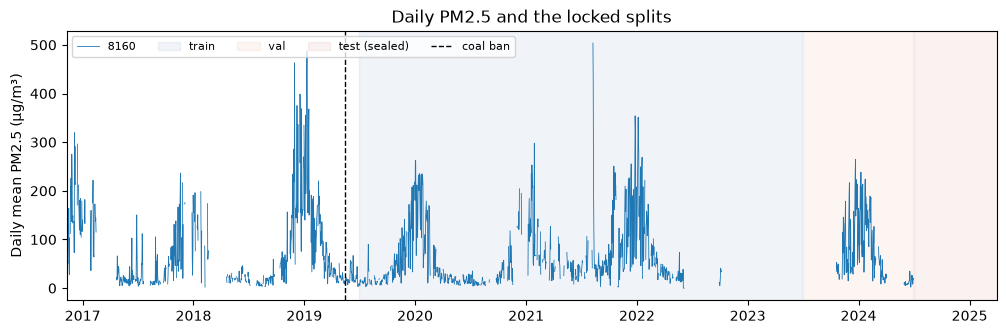

In [5]:
from uaq.periods import assign_split
fig, ax = plt.subplots(figsize=(12, 3.5))
seen = daily[daily["date"] <= VAL_END]                      # test-winter PM2.5 is never plotted
for sid, g in seen.groupby("station_id"):
    ax.plot(g["date"], g["pm25_daily"], lw=0.6, label=sid)
colors = {"train": "#4C72B0", "val": "#DD8452", "test": "#C44E52"}
for name, s in fp["split"].items():
    ax.axvspan(pd.Timestamp(s["start"]), pd.Timestamp(s["end"]), color=colors[name], alpha=0.08,
               label="test (sealed)" if name == "test" else name)
ax.set_xlim(daily["date"].min(), pd.Timestamp(fp["split"]["test"]["end"]))
ax.axvline(pd.Timestamp(cfg["structural_break"]), color="k", ls="--", lw=1, label="coal ban")
ax.set_ylabel("Daily mean PM2.5 (µg/m³)"); ax.legend(ncol=5, fontsize=8); ax.set_title("Daily PM2.5 and the locked splits")
plt.show()

### A.4 · Coverage by smog season
Share of Nov–Feb days with a valid daily mean. The station is usable if training holds at least 240 valid smog-season days in total (two full winters’ worth; partial winters count, because the model trains on every valid day) and the validation and test winters each have ≥75% coverage. good_train_winters is reported for the write-up only.

The coverage heatmap and eligibility table use the test winter's **availability only** (share of days with a valid daily mean, never PM2.5 values); the eligibility rule needs it.

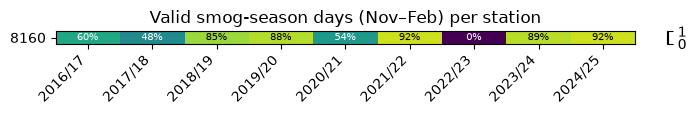

,good_train_winters,train_valid_smog_days,val_cov,test_cov_min,eligible
station_id,,,,,
8160,2,283,0.893,0.925,True


In [6]:
from uaq import audit_forecast as af
cov = af.coverage_table(daily, cfg)
af.plot_coverage(cov, cfg["quality"]["min_valid_frac"]); plt.show()
elig = af.eligibility(cov, cfg)
elig

### A.5 · Before and after the raw-coal ban
Why the core study starts in July 2019: the level shifts at the ban, so pre-ban winters are kept only for the optional sensitivity experiment (H5).

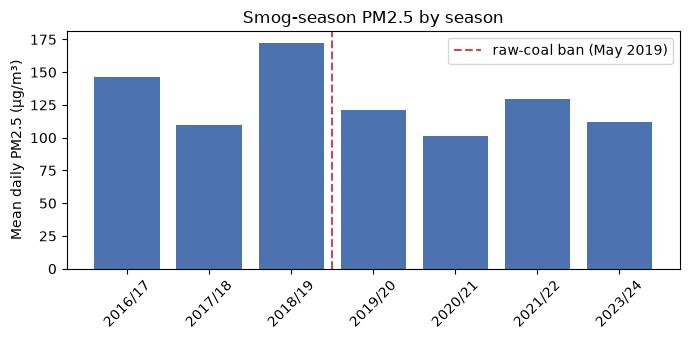

In [7]:
af.plot_season_means(daily, cfg); plt.show()

### A.6 · Daily cycle in winter
Motivates the hourly features (yesterday evening's mean and maximum). Hours are local time.

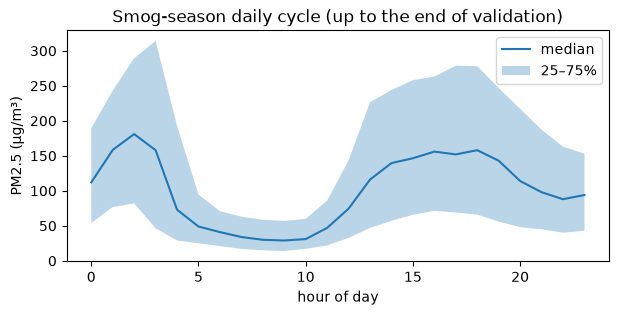

In [8]:
from uaq.periods import in_months
local_date = hourly["ts_local"].dt.tz_localize(None).dt.normalize()
h = hourly[in_months(local_date, cfg["smog_months"]).values & (local_date <= VAL_END).values]   # test winter sealed
prof = h.groupby(h["ts_local"].dt.hour)["pm25"].quantile([0.25, 0.5, 0.75]).unstack()
ax = prof[0.5].plot(figsize=(7, 3), label="median")
ax.fill_between(prof.index, prof[0.25], prof[0.75], alpha=0.3, label="25–75%")
ax.set_xlabel("hour of day"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend(); ax.set_title("Smog-season daily cycle (up to the end of validation)")
plt.show()

### A.7 · Event threshold (training smog-season days only)
Rule: the lowest official line exceeded on ≤60% of training days; otherwise the training 75th percentile, labelled study-defined.

In [9]:
from uaq import thresholds
rates = af.threshold_table(daily, cfg)
display(rates.round(3))
thr_name, thr, why = thresholds.choose(rates, cfg)
print(f"Chosen: {thr_name} = {thr} µg/m³\n{why}")

,threshold,ug_m3,base_rate
0,mns_4585_2025,37.5,0.894
1,mns_4585_2016,50.0,0.813
2,who_it1_2021,75.0,0.661
3,train_p75,170.8,0.251


Chosen: train_p75 = 170.8 µg/m³
Every official threshold is exceeded too often in training (mns_4585_2025 89%, mns_4585_2016 81%, who_it1_2021 66%), so a study-defined training percentile is used. Report the official rates as context.


### A.8 · Baselines the neural networks must beat
Persistence (tomorrow = today), 3-day mean, and climatology (fitted on training only). Validation scores are the bar; the test winter is not scored here.

In [10]:
stations = elig.index[elig["eligible"]].tolist()
scores = af.baseline_scores(daily, stations, thr, cfg)
scores.round(3)

,group,model,n,mae,rmse,r2,events,base_rate,tp,false_alarms,missed,precision,recall,f1
0,train,persistence,263,48.460,66.033,0.170,68,0.259,39,29,29,0.574,0.574,0.574
1,val,persistence,105,49.240,62.469,-0.018,22,0.210,8,14,14,0.364,0.364,0.364
2,train,mean3d,274,50.943,67.009,0.140,70,0.255,33,19,37,0.635,0.471,0.541
3,val,mean3d,106,51.166,61.576,0.004,22,0.208,8,7,14,0.533,0.364,0.432
4,train,climatology,283,47.013,58.492,0.343,71,0.251,18,16,53,0.529,0.254,0.343
5,val,climatology,108,50.876,61.762,0.004,22,0.204,4,11,18,0.267,0.182,0.216


### A.9 · Save the audit report
Writes `outputs/audit_forecast/audit_report.md` plus the tables and figures above.
Record the decisions (usable station, threshold, baseline scores) in the plan doc.

In [11]:
report = af.run()
print(report.read_text()[:1500])

# Forecasting data audit

- Raw files read: 3181
- Units seen: ['µg/m³'] (expected µg/m³)
- Hourly rows: 61,607 across 1 station(s)
- Date range: 2016-11-09 17:00:00 → 2025-03-04 12:00:00
- Duplicate station-hours merged: 0
- Unparseable timestamps dropped: 0
- Hourly values flagged implausible (>1500): 0

## Decisions

- **Usable station(s):** 8160
- **Event threshold:** train_p75 = 170.8 µg/m³. Every official threshold is exceeded too often in training (mns_4585_2025 89%, mns_4585_2016 81%, who_it1_2021 66%), so a study-defined training percentile is used. Report the official rates as context.
- **Splits:** train 2019-07-01→2023-06-30, val 2023-07-01→2024-06-30, test 2024-07-01→2025-03-31 (sealed).

## Station eligibility

|   station_id |   good_train_winters |   train_valid_smog_days |   val_cov |   test_cov_min | eligible   |
|-------------:|---------------------:|------------------------:|----------:|---------------:|:-----------|
|         8160 |                    2 |          

## Part B · Network data audit (agaar.gov.mn, Ulaanbaatar)

**Goal:** decide which stations enter the network-design experiment and lock the event threshold.

**Needs:** the agaar archive copied from data-mn into `data/raw/agaar/`
(`agaar-stations.csv` and `daily/agaar-daily-YYYY-MM.csv`).
Daily files are used, not hourly: the site deletes hourly concentrations once a month is validated.

Logic: `src/uaq/agaar.py` (loading + cleaning) and `src/uaq/audit_network.py`.

In [2]:
display(pd.DataFrame(cfg["network"]["split"]).T.rename_axis("split"))
print("Cleaning rules:", cfg["network"]["cleaning"])

,start,end
split,,
train,2025-10-01,2025-12-31
val,2026-01-01,2026-01-31
test,2026-02-01,2026-03-31


Cleaning rules: {'above_pm10_ratio': 1.1, 'above_pm10_min': 50, 'spike_ratio': 5, 'spike_min': 150, 'flat_days': 5}


### B.1 · Load and clean
Same rules as data-mn's own build: drop negative values, PM2.5 above PM10, spikes (>5× that day's cross-station median and >150), and stuck sensors (same value 5+ days).

In [3]:
from uaq import audit_network as an
r = an.prepare(cfg)
daily, stations = r["daily"], r["stations"]
print("Station-days by cleaning outcome:")
display(daily["dropped_reason"].replace("", "kept").value_counts().to_frame("station-days"))
names = stations.set_index("station_code")["name_mn"]
stations

Station-days by cleaning outcome:


,station-days
dropped_reason,
kept,6925
above_pm10,80
spike,17
flat,6
negative,2


,station_code,name_mn,lat,lon
0,12301,Бөхийн өргөө,47.917550,106.937478
1,12303,Ургах наран,47.866467,107.118775
2,12304,Шархад,47.933744,107.010403
3,12305,Амгалан-3,47.913503,106.997911
4,12306,Шинэ 100 айл төв,47.904450,106.980743
5,12401,1-р хороолол,47.918069,106.847819
6,12402,Толгойт-1,47.922489,106.794842
7,12403,Баянхошуу-6,47.863956,106.931942
8,12404,5 Шар,47.912121,106.814642
9,12501,100 айл,47.932892,106.921361


### B.2 · Coverage by split → eligible stations
A station is eligible with ≥75% valid days in train **and** validation **and** test.

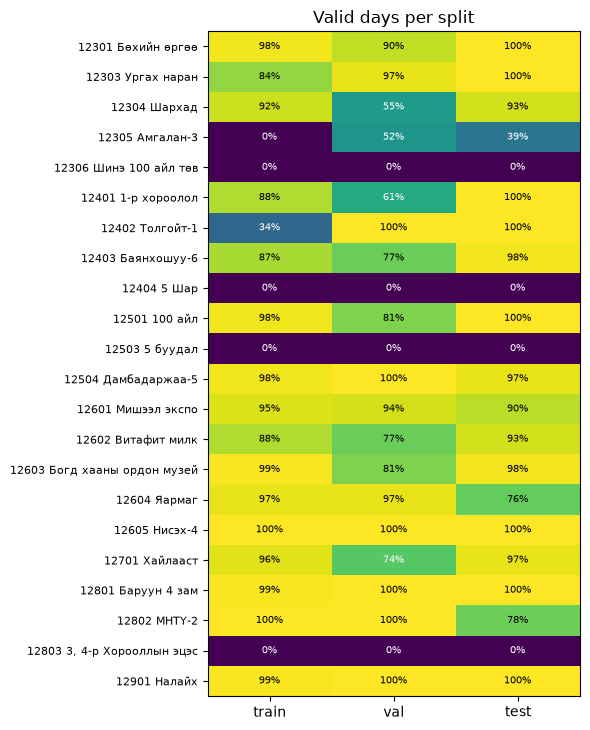

13 eligible: ['12301', '12303', '12403', '12501', '12504', '12601', '12602', '12603', '12604', '12605', '12801', '12802', '12901']


In [4]:
an.plot_coverage(r["coverage"], names, cfg["quality"]["min_valid_frac"]); plt.show()
print(len(r["eligible"]), "eligible:", r["eligible"])

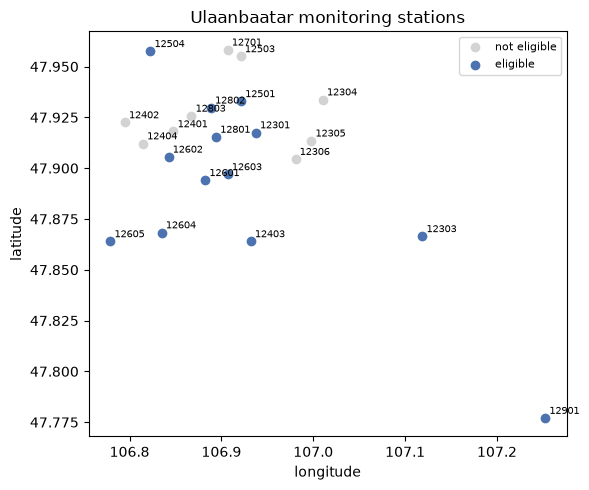

In [5]:
an.plot_map(stations, r["eligible"]); plt.show()

### B.3 · The winter in one picture
City median and the range across eligible stations, with the splits shaded. Note the validation month (January) is the most polluted; the test months (Feb–Mar) are cleaner.

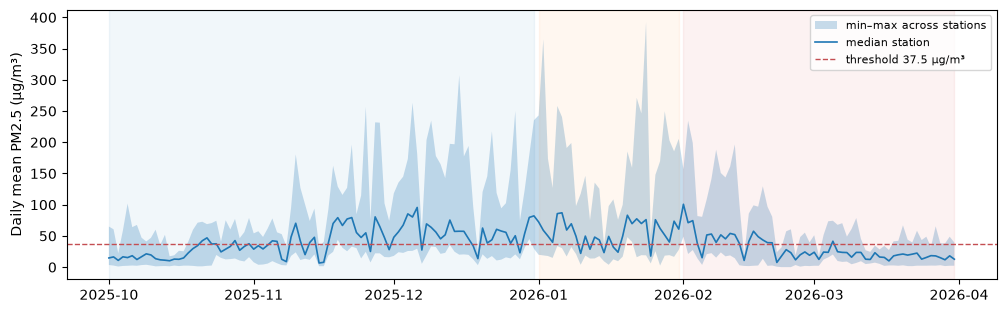

In [6]:
w = r["wide"]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.fill_between(w.index, w.min(axis=1), w.max(axis=1), alpha=0.25, label="min–max across stations")
ax.plot(w.index, w.median(axis=1), lw=1.2, label="median station")
ax.axhline(r["threshold"], color="#C44E52", ls="--", lw=1, label=f"threshold {r['threshold']} µg/m³")
for name, s in cfg["network"]["split"].items():
    ax.axvspan(pd.Timestamp(s["start"]), pd.Timestamp(s["end"]), alpha=0.06, color={"train": "C0", "val": "C1", "test": "C3"}[name])
ax.set_ylabel("Daily mean PM2.5 (µg/m³)"); ax.legend(fontsize=8); plt.show()

### B.4 · How redundant are the stations?
High correlation between stations is what makes a smaller network possible, and what makes the choice non-trivial: the best set avoids keeping near-duplicates.

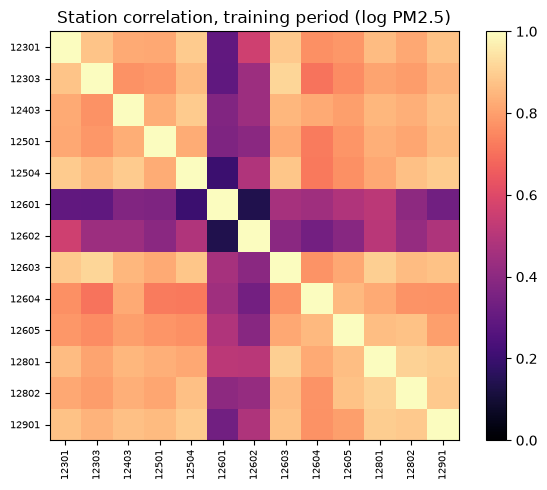

In [7]:
an.plot_correlation(r["wide"], r["masks"]["train"]); plt.show()

**Check before trusting the GA:** a station that correlates weakly with every other one is either a genuinely different micro-environment (worth keeping) or a faulty sensor (should be excluded). Plot any such station against the city median below and decide; record the decision in the report.

,mean correlation with other stations
station_code,
12601,0.36
12602,0.42
12604,0.71
12501,0.74
12303,0.74


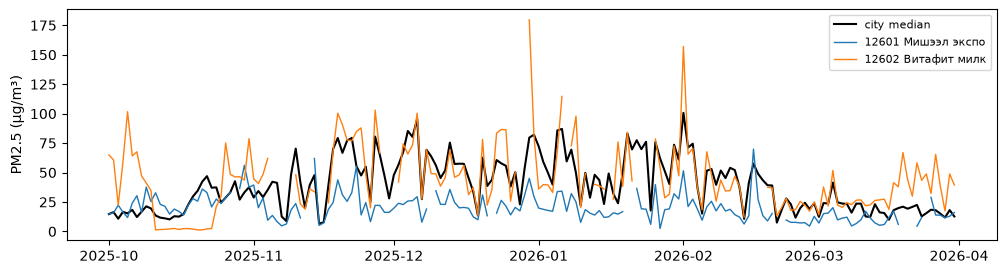

In [8]:
corr = np.log1p(r["wide"][r["masks"]["train"]]).corr()
mean_corr = (corr.sum() - 1) / (len(corr) - 1)
display(mean_corr.sort_values().round(2).to_frame("mean correlation with other stations").head(5))
odd = mean_corr.nsmallest(2).index.tolist()
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(r["wide"].index, r["wide"].median(axis=1), color="k", lw=1.5, label="city median")
for c in odd:
    ax.plot(r["wide"].index, r["wide"][c], lw=1, label=f"{c} {names[c]}")
ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend(fontsize=8); plt.show()

### B.5 · Event threshold (training station-days)

In [9]:
display(r["rates"].round(3))
print(f"Chosen: {r['threshold_name']} = {r['threshold']} µg/m³\n{r['threshold_why']}")

,threshold,ug_m3,base_rate
0,mns_4585_2025,37.5,0.485
1,mns_4585_2016,50.0,0.351
2,who_it1_2021,75.0,0.169
3,train_p75,61.3,0.250


Chosen: mns_4585_2025 = 37.5 µg/m³
Lowest official threshold exceeded on ≤ 60% of training days (rates: mns_4585_2025 48%).


### B.6 · Save the audit report

In [10]:
report = an.run()
print(report.read_text()[:1500])

# Network data audit (agaar.gov.mn, Ulaanbaatar)

- Daily files read: 21
- Ulaanbaatar stations in catalogue: 22
- Station-days by cleaning outcome: {'kept': 6925, 'above_pm10': 80, 'spike': 17, 'flat': 6, 'negative': 2}

## Decisions

- **Eligible stations:** 13 (≥75% valid days in train, val AND test) → 12301, 12303, 12403, 12501, 12504, 12601, 12602, 12603, 12604, 12605, 12801, 12802, 12901
- **Exhaustive search feasible for every k:** yes
- **Event threshold:** mns_4585_2025 = 37.5 µg/m³. Lowest official threshold exceeded on ≤ 60% of training days (rates: mns_4585_2025 48%).
- **Splits:** train 2025-10-01→2025-12-31, val 2026-01-01→2026-01-31, test 2026-02-01→2026-03-31 (sealed).

## Coverage by split

|   station_code |   train |   val |   test | name                   |
|---------------:|--------:|------:|-------:|:-----------------------|
|          12301 |    0.98 |  0.90 |   1.00 | Бөхийн өргөө           |
|          12303 |    0.84 |  0.97 |   1.00 | Ургах наран            |

## Part C · Weather and forecast features (ERA5)

**Goal:** download hourly weather once (Open-Meteo, ERA5 reanalysis), turn it into daily weather by local day, and build the feature table for next-day PM2.5 forecasting.

**No-leakage rule:** a row is the forecast issued at the end of local day D for day D+1. Every feature uses day D or earlier. The only exception is the labelled `*_tplus1` weather columns, which exist only for the upper-bound experiment (`features.include_future_weather: true`) and are excluded by `feature_columns()` unless `future=True`.

All logic lives in `src/uaq/weather.py` and `src/uaq/features.py`; this notebook only calls it.

### C.1 · Download once
Requests one calendar year at a time in UTC (Mongolia used daylight saving time in 2015–2016) and converts to local time. Skipped if the file already exists.

In [2]:
path = weather.download(cfg)
wh = weather.load_hourly(cfg)
print(f"{len(wh):,} hourly rows, {wh['ts_local'].min()} → {wh['ts_local'].max()}")
print(json.dumps(json.loads(path.with_name(path.stem + ".meta.json").read_text()), indent=2))

/Users/user/Desktop/neural/data/raw/weather/open_meteo_ub_hourly.csv exists; not downloading (use force=True to refresh)
76,704 hourly rows, 2016-07-01 09:00:00+09:00 → 2025-04-01 07:00:00+08:00
{
  "latitude": 48.0,
  "longitude": 107.0,
  "elevation": 1302.0,
  "hourly_units": {
    "time": "iso8601",
    "temperature_2m": "\u00b0C",
    "relative_humidity_2m": "%",
    "surface_pressure": "hPa",
    "wind_speed_10m": "m/s",
    "wind_direction_10m": "\u00b0",
    "boundary_layer_height": "m"
  },
  "variables": [
    "temperature_2m",
    "relative_humidity_2m",
    "surface_pressure",
    "wind_speed_10m",
    "wind_direction_10m",
    "boundary_layer_height"
  ],
  "requested_latitude": 47.92,
  "requested_longitude": 106.92,
  "downloaded_utc": "2026-10-27T22:40:07+00:00",
  "models": "era5",
  "source": "https://archive-api.open-meteo.com/v1/archive",
  "attribution": "Open-Meteo (Zippenfenig, 2023); ERA5, Copernicus Climate Change Service"
}


In [3]:
wd = weather.to_daily(wh)
display(wd.describe().T.round(2))

,count,mean,min,25%,50%,75%,max,std
date,3197,2020-11-15 00:00:00,2016-07-01 00:00:00,2018-09-08 00:00:00,2020-11-15 00:00:00,2023-01-23 00:00:00,2025-04-01 00:00:00,NaN
n_hours,3197.0,23.992493,8.0,24.0,24.0,24.0,25.0,0.325117
temp_mean,3197.0,-0.031526,-34.854167,-14.225,1.729167,13.633333,27.333333,14.949013
temp_min,3197.0,-5.897904,-40.8,-20.0,-3.9,7.5,20.8,14.814665
temp_range,3197.0,12.055114,1.4,9.2,12.0,14.9,24.2,3.847867
rh_mean,3197.0,63.260324,12.916667,53.375,66.041667,74.708333,96.0,15.040063
pressure_mean,3197.0,867.521117,840.883333,863.820833,867.575,871.204167,887.983333,5.587577
wind_mean,3197.0,2.532377,0.79375,1.787917,2.33125,3.05125,8.964167,1.045428
calm_hours,3197.0,2.269315,0.0,0.0,1.0,4.0,19.0,3.061178
wind_u,3197.0,0.300892,-5.286634,-0.623072,0.211433,1.179754,7.370309,1.313427


#### BLH availability rule (fixed before any model is trained)
Keep `w_blh_mean`, `w_blh_night` and `w_blh_night_change` only if each BLH column is present on ≥ 95% of smog-season days in **every** split (train, val, test). Otherwise they go in `features.drop_columns` and `feature_columns()` excludes them.

In [4]:
fsp = cfg["forecast"]["periods"]["split"]
d = wd.assign(split=assign_split(wd["date"], fsp).values, smog=in_months(wd["date"], cfg["smog_months"]).values)
d = d[d["smog"] & d["split"].isin(["train", "val", "test"])]
blh = [c for c in ("blh_mean", "blh_night") if c in wd]
share = d.groupby("split")[blh].agg(lambda s: s.notna().mean()).reindex(["train", "val", "test"]) if blh else pd.DataFrame()
display(share.round(3).rename_axis("non-missing share, smog-season days"))
keep_blh = bool(blh) and bool((share >= 0.95).all().all())
blh_feats = ["w_blh_mean", "w_blh_night", "w_blh_night_change"]
drop = cfg["features"].get("drop_columns", [])
print("Rule outcome:", "KEEP the BLH features" if keep_blh else "DROP the BLH features (some split < 95%)")
assert keep_blh != set(blh_feats) <= set(drop), "features.drop_columns in the config disagrees with the rule: update it"
print("features.drop_columns:", drop)

,blh_mean,blh_night
"non-missing share, smog-season days",,
train,1.000,1.000
val,0.512,0.512
test,1.000,1.000


Rule outcome: DROP the BLH features (some split < 95%)
features.drop_columns: ['w_blh_mean', 'w_blh_night', 'w_blh_night_change']


### C.2 · Weather vs PM2.5, training smog-season days only
Only **training** days (Nov–Feb, valid daily means) are looked at here. Exploring validation or test days would let what we see leak into feature and model choices.

In [5]:
station = str(cfg["forecast"]["input"]["location_ids"][0])
pm_hourly = load_hourly(cfg)
pm_hourly = pm_hourly[pm_hourly["station_id"] == station]
pm_daily = to_daily(pm_hourly, cfg["quality"]["min_hours_per_day"])

m = pm_daily.merge(wd, on="date", how="inner")
train = ((assign_split(m["date"], cfg["forecast"]["periods"]["split"]) == "train").values
         & in_months(m["date"], cfg["smog_months"]).values & m["valid"].values)
tr = m[train]
wcols = [c for c in wd.columns if c not in ("date", "n_hours")]
rho = tr[wcols].corrwith(tr["pm25_daily"], method="spearman").sort_values()
print(f"{len(tr)} training smog-season days")
display(rho.round(2).to_frame("Spearman ρ with same-day PM2.5"))

283 training smog-season days


,Spearman ρ with same-day PM2.5
blh_mean,-0.79
wind_mean,-0.63
blh_night,-0.54
temp_min,-0.36
temp_mean,-0.35
wind_u,-0.31
pressure_mean,-0.08
rh_mean,-0.03
temp_range,0.21
wind_v,0.26


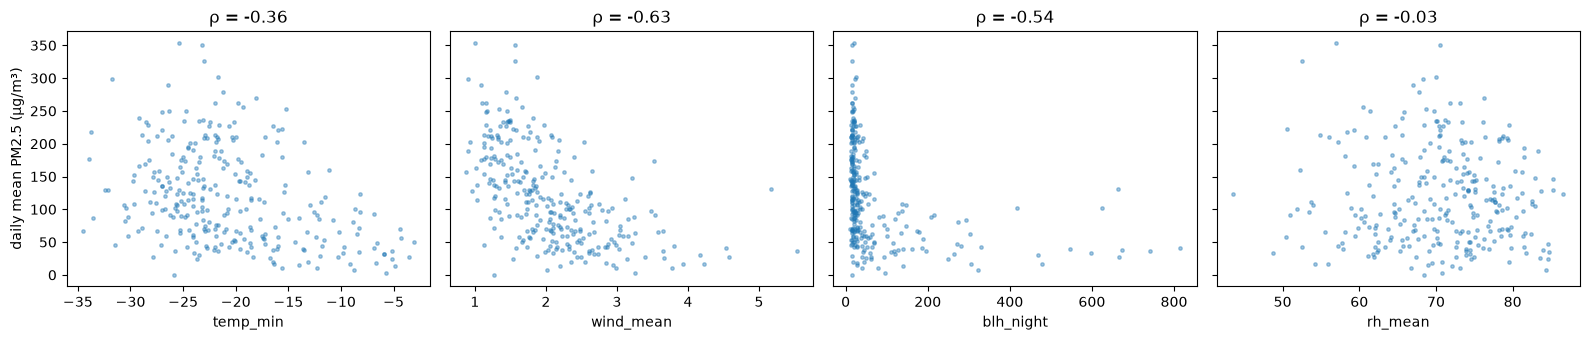

In [6]:
panel = [c for c in ("temp_min", "wind_mean", "blh_night", "rh_mean") if c in tr]
fig, axes = plt.subplots(1, len(panel), figsize=(4 * len(panel), 3.5), sharey=True)
for ax, c in zip(np.atleast_1d(axes), panel):
    ax.scatter(tr[c], tr["pm25_daily"], s=6, alpha=0.4)
    ax.set_xlabel(c); ax.set_title(f"ρ = {rho[c]:.2f}")
np.atleast_1d(axes)[0].set_ylabel("daily mean PM2.5 (µg/m³)")
fig.tight_layout(); plt.show()

### C.3 · Build the feature table
One row per issue day D for the forecasting station.

In [7]:
feat = features.build(pm_daily, pm_hourly, cfg, wd)
with_w = features.feature_columns(feat, drop=drop)
without_w = features.feature_columns(feat, weather=False, drop=drop)
print(f"{len(feat):,} issue days; {len(with_w)} features with weather, {len(without_w)} without")
display(feat.head())

3,038 issue days; 27 features with weather, 16 without


,date,pm_lag0,pm_lag1,pm_lag2,pm_lag3,pm_lag6,pm_mean3d,pm_mean7d,pm_std7d,pm_evening,pm_last_hour,pm_max_hourly,y,target_date,doy_sin,doy_cos,dow_sin,dow_cos,weekend,w_temp_mean,w_temp_min,w_temp_range,w_rh_mean,w_pressure_mean,w_wind_mean,w_calm_hours,w_wind_u,w_wind_v,w_blh_mean,w_blh_night,w_temp_mean_change,w_pressure_mean_change,w_blh_night_change,split,smog,covid,season_year
0,2016-11-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.816667,30.2,36.6,118.795833,2016-11-10,-0.760720,0.649080,0.433884,-0.900969,0,-10.195833,-15.2,11.2,78.666667,861.725000,2.275000,0,-0.219162,-1.246461,136.458333,35.000000,4.012500,-9.166667,19.285714,outside,True,False,2016
1,2016-11-10,118.795833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,155.833333,81.6,266.5,137.287500,2016-11-11,-0.749442,0.662070,-0.433884,-0.900969,0,-13.504167,-18.3,8.7,82.208333,860.062500,2.037917,1,0.832589,-0.599958,260.208333,147.142857,-3.308333,-1.662500,112.142857,outside,True,False,2016
2,2016-11-11,137.287500,118.795833,NaN,NaN,NaN,128.041667,NaN,NaN,225.683333,137.0,257.1,61.583333,2016-11-12,-0.737943,0.674863,-0.974928,-0.222521,1,-14.975000,-19.8,10.4,81.833333,858.433333,1.895417,5,0.214050,-0.974333,178.750000,20.000000,-1.470833,-1.629167,-127.142857,outside,True,False,2016
3,2016-11-12,61.583333,137.287500,118.795833,NaN,NaN,105.888889,NaN,NaN,66.800000,34.6,108.8,50.616667,2016-11-13,-0.726225,0.687457,-0.781831,0.623490,1,-16.375000,-23.7,13.9,79.041667,855.533333,2.614167,0,-2.412038,0.837519,88.750000,30.000000,-1.400000,-2.900000,10.000000,outside,True,False,2016
4,2016-11-13,50.616667,61.583333,137.287500,118.795833,NaN,83.162500,92.070833,42.452751,123.900000,75.5,227.3,136.491667,2016-11-14,-0.714292,0.699848,0.000000,1.000000,0,-12.208333,-16.6,6.9,82.833333,858.166667,3.629583,0,1.439425,-2.549482,350.833333,28.571429,4.166667,2.633333,-1.428571,outside,True,False,2016


### C.4 · Usable rows per split (smog-season targets)

**Fair weather ablation:** the with-weather and no-weather models are trained and scored on the **same rows**, those complete for the with-weather feature set (`ablation_rows` below). The no-weather model just ignores the `w_*` columns, so any difference comes from the features, not from different days.

In [8]:
s = feat[feat["smog"]]
usable = pd.DataFrame({
    "issue days": s.groupby("split").size(),
    "target present": s[s["y"].notna()].groupby("split").size(),
    "complete with weather": features.complete_rows(s, with_w).groupby("split").size(),
    "complete without weather": features.complete_rows(s, without_w).groupby("split").size(),
}).reindex(["train", "val", "test", "outside"]).fillna(0).astype(int)
ablation_rows = features.complete_rows(feat, with_w)          # use for BOTH models in the ablation
usable["ablation rows (both models)"] = ablation_rows[ablation_rows["smog"]].groupby("split").size()
usable = usable.fillna(0).astype(int)
display(usable)

,issue days,target present,complete with weather,complete without weather,ablation rows (both models)
split,,,,,
train,481,283,211,211,211
val,121,108,89,89,89
test,120,111,104,104,104
outside,351,226,86,86,86


In [9]:
seq_cols = (["pm_lag0", "pm_evening", "pm_max_hourly", "doy_sin", "doy_cos"]
            + [c for c in with_w if c.startswith("w_") and not c.endswith("_change")])
T = cfg["forecast"]["history_days"]
X, y, issue = features.make_sequences(feat, seq_cols, T)
print("X:", X.shape, " y:", y.shape)
meta = feat.set_index("date").loc[issue, ["split", "smog"]]
display(pd.crosstab(meta["split"], meta["smog"], margins=True))

X: (635, 14, 14)  y: (635,)


smog,False,True,All
split,,,
outside,89,30,119
test,58,97,155
train,113,160,273
val,22,66,88
All,282,353,635


### C.5 · Missing values per feature (training, smog season)

In [10]:
tr_smog = feat[(feat["split"] == "train") & feat["smog"]]
display(tr_smog[with_w].isna().mean().sort_values(ascending=False).round(3).to_frame("share missing"))

,share missing
pm_lag0,0.410
pm_lag1,0.410
pm_lag3,0.407
pm_lag6,0.407
pm_mean3d,0.407
pm_lag2,0.405
pm_mean7d,0.397
pm_std7d,0.397
pm_evening,0.389
pm_last_hour,0.383


### C.6 · Save
`data/processed/` is git-ignored.

In [11]:
out = ROOT / "data" / "processed" / f"features_{station}.csv"
out.parent.mkdir(parents=True, exist_ok=True)
feat.to_csv(out, index=False)
print("Saved", out)

Saved /Users/user/Desktop/neural/data/processed/features_8160.csv
